# Staffing Boston's 311 city service teams

IE 5374 hackathon. Team: Nishanth Manoharan, Ramgopal Reddy Alumalla, Aryan Patil.

This notebook calls the same functions in `src/boston311/` as the web app, so the analysis and the product can't drift apart. Before running it, build the data:

```
uv run python scripts/download_data.py
uv run python scripts/build_processed.py
```

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from boston311.config import DEPARTMENTS, INTERIM_DIR, PROCESSED_DIR
from boston311.data.aggregate import RESIDENT_SOURCES, query_service_stats

pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
NAMES = {code: d["name"] for code, d in DEPARTMENTS.items()}

monthly = pd.read_csv(PROCESSED_DIR / "monthly_demand.csv")
daily = pd.read_csv(PROCESSED_DIR / "daily_profile.csv", parse_dates=["date"])
sla = pd.read_csv(PROCESSED_DIR / "sla_profile.csv")
types = pd.read_csv(PROCESSED_DIR / "request_types.csv")
stats = pd.read_parquet(PROCESSED_DIR / "service_stats.parquet")

## 2. Exploring the 311 data

The pipeline keeps the four departments in scope (by the `department` column) from the 2023, 2024 and January to September 2025 files. 2025 is only used to check the forecast.

### 2.1 The 2024 counts reproduce the brief

In [2]:
monthly["year"] = monthly["month"].str[:4]
by_year = monthly.pivot_table(index="department", columns="year", values="requests",
                              aggfunc="sum").reindex(list(DEPARTMENTS))
by_year["brief 2024"] = [d["requests_2024"] for d in DEPARTMENTS.values()]
by_year["2024 matches"] = by_year["2024"] == by_year["brief 2024"]
by_year.rename(columns={"2025": "2025 (Jan-Sep)"})

year,2023,2024,2025 (Jan-Sep),brief 2024,2024 matches
department,,,,,
PWDx,171268,157610,105437,157610,True
BTDT,75314,81447,61696,81447,True
PARK,17541,18736,12075,18736,True
ISD,18123,18624,13874,18624,True


### 2.2 Monthly demand is seasonal, and each department peaks differently

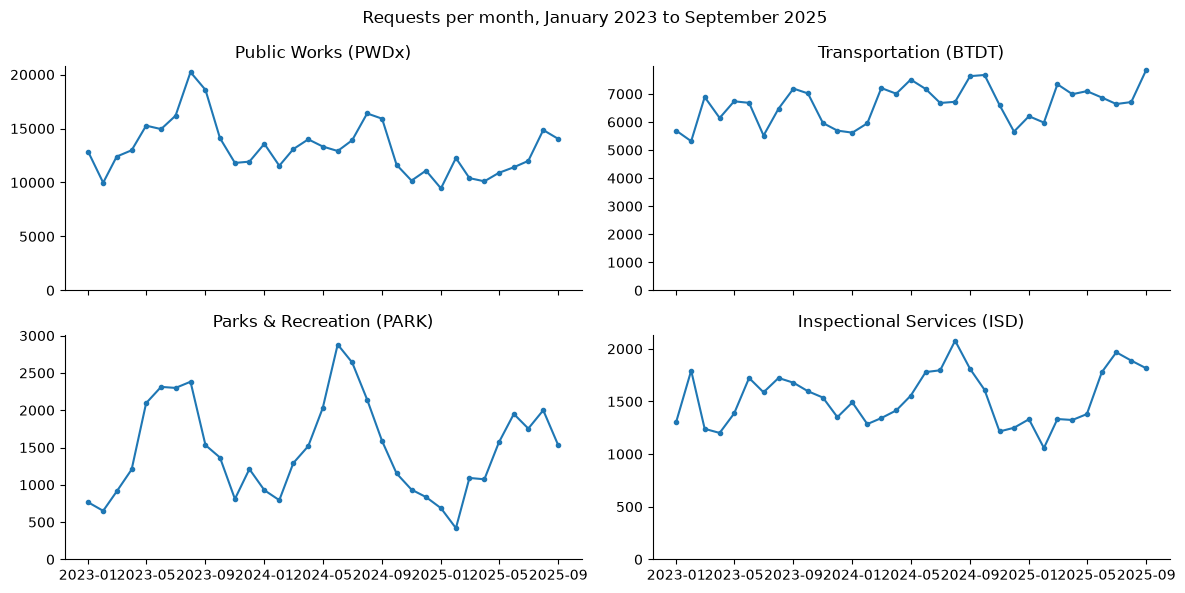

In [3]:
monthly["date"] = pd.to_datetime(monthly["month"])
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, code in zip(axes.flat, DEPARTMENTS):
    d = monthly[monthly["department"] == code]
    ax.plot(d["date"], d["requests"], marker=".")
    ax.set_title(f"{NAMES[code]} ({code})")
    ax.set_ylim(bottom=0)
fig.suptitle("Requests per month, January 2023 to September 2025")
fig.tight_layout()

In [4]:
# each month's 2024 requests divided by that department's 2024 monthly average
m24 = monthly[monthly["year"] == "2024"].copy()
m24["month_num"] = m24["month"].str[5:].astype(int)
season = m24.pivot(index="department", columns="month_num", values="requests")
season = season.div(season.mean(axis=1), axis=0).reindex(list(DEPARTMENTS))
season["peak / trough"] = season.max(axis=1) / season.min(axis=1)
season.round(2)

month_num,1,2,3,4,5,6,7,8,9,10,11,12,peak / trough
department,,,,,,,,,,,,,
PWDx,1.030,0.880,1.000,1.070,1.020,0.980,1.060,1.250,1.210,0.890,0.770,0.850,1.610
BTDT,0.830,0.880,1.060,1.030,1.110,1.060,0.980,0.990,1.120,1.130,0.970,0.830,1.370
PARK,0.590,0.510,0.830,0.970,1.300,1.850,1.690,1.370,1.020,0.740,0.600,0.540,3.630
ISD,0.960,0.830,0.860,0.910,1.000,1.150,1.160,1.340,1.170,1.040,0.780,0.810,1.710


### 2.3 Requests arrive every day, but far fewer on weekends

In [5]:
daily["weekday"] = daily["date"].dt.day_name().str[:3]
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = daily.pivot_table(index="department", columns="weekday", values="requests",
                            aggfunc="mean")[order].reindex(list(DEPARTMENTS))
weekday.round(0)

weekday,Mon,Tue,Wed,Thu,Fri,Sat,Sun
department,,,,,,,
PWDx,538.000,561.000,535.000,482.000,453.000,305.000,275.000
BTDT,232.000,249.000,252.000,247.000,234.000,153.000,134.000
PARK,61.000,60.000,61.000,60.000,52.000,27.000,26.000
ISD,63.000,64.000,60.000,58.000,54.000,29.000,24.000


### 2.4 On-time rates

Requests with no target date count as workload but are left out of the on-time rate (working assumption 3). The brief's figures count them as on time, so Public Works and Transportation come out lower here. These are the numbers the simulator's 2024 baseline is compared with.

In [6]:
s24 = stats[stats["year"] == 2024]
on_time = pd.DataFrame(query_service_stats("on_time_rate", "department", {"year": 2024}))
on_time = on_time.set_index("department").reindex(list(DEPARTMENTS))
on_time["brief"] = [d["on_time_2024"] for d in DEPARTMENTS.values()]
on_time["no target date"] = s24["on_time"].isna().groupby(s24["department"]).mean()
on_time

,on_time_rate,brief,no target date
department,,,
PWDx,0.873,0.900,0.186
BTDT,0.489,0.500,0.020
PARK,0.930,0.930,0.022
ISD,0.723,0.720,0.004


### 2.5 Target windows

The simulator samples each request's target window from this 2024 mix. Parks has many 365-day targets, so its on-time rate says little about how fast it works.

In [7]:
bins = [-1, 1, 3, 7, 14, 30, 90, 364, 10_000]
labels = ["<=1", "2-3", "4-7", "8-14", "15-30", "31-90", "91-364", "365+"]
sla["window"] = pd.cut(sla["target_days"], bins, labels=labels)
sla["window"] = sla["window"].cat.add_categories("none").fillna("none")
windows = sla.pivot_table(index="department", columns="window", values="share",
                          aggfunc="sum", observed=False).reindex(list(DEPARTMENTS))
(windows * 100).round(1)

window,<=1,2-3,4-7,8-14,15-30,31-90,91-364,365+,none
department,,,,,,,,,
PWDx,26.600,29.400,17.500,2.300,4.600,0.600,0.100,0.200,18.600
BTDT,42.300,33.000,7.400,2.700,11.300,0.900,0.200,0.100,2.000
PARK,4.100,4.500,15.600,16.000,0.500,0.100,0.100,57.000,2.200
ISD,3.300,10.200,10.600,3.400,30.000,8.300,25.500,8.300,0.400


### 2.6 Who logs requests

City staff (Employee Generated and the City Worker App) log more than half of the requests in these four departments, more than the brief's 42% across all departments. Section 6 compares their on-time rates and close times with residents' requests.

In [8]:
source = s24.pivot_table(index="department", columns="source", values="year",
                         aggfunc="size", fill_value=0).reindex(list(DEPARTMENTS))
share = source.div(source.sum(axis=1), axis=0)
share["resident total"] = share[sorted(RESIDENT_SOURCES)].sum(axis=1)
share["staff total"] = 1 - share["resident total"]
(share * 100).round(1)

source,Citizens Connect App,City Worker App,Constituent Call,Employee Generated,Self Service,resident total,staff total
department,,,,,,,
PWDx,21.600,16.100,22.500,33.500,6.200,50.400,49.600
BTDT,32.900,0.300,4.900,61.300,0.600,38.400,61.600
PARK,27.400,23.800,11.100,36.500,1.200,39.700,60.300
ISD,13.300,1.300,42.700,39.000,3.800,59.700,40.300


### 2.7 Request types

158 request types appear in the four departments in 2024. A few types make up most of each department's work. The intake assistant routes to these types, and each type's department and queue come from this table.

In [9]:
print(types.groupby("department")["request_type"].count().reindex(list(DEPARTMENTS)))
top5 = types.groupby("department").head(5)  # types is sorted by requests
top5 = top5.assign(order=top5["department"].map(list(DEPARTMENTS).index))
top5.sort_values(["order", "requests"], ascending=[True, False]).set_index(
    ["department", "request_type"])[["requests", "median_days_to_close", "queue"]]

department
PWDx    62
BTDT    22
PARK    12
ISD     62
Name: request_type, dtype: int64


requests  \
department request_type                                            
PWDx       Requests for Street Cleaning                    20564   
           Improper Storage of Trash (Barrels)             20340   
           CE Collection                                   18011   
           Schedule a Bulk Item Pickup                     11828   
           Missed Trash/Recycling/Yard Waste/Bulk Item     10588   
BTDT       Parking Enforcement                             63064   
           Sign Repair                                      4876   
           Abandoned Vehicles                               4759   
           Traffic Signal Inspection                        3773   
           New Sign  Crosswalk or Pavement Marking           945   
PARK       Tree Maintenance Requests                        8355   
           Ground Maintenance                               3183   
           New Tree Requests                                2577   
           Equipment Repair                                 2441   
           Tree Emergencies                                  727   
ISD        Rodent Activity                                  4936   
           Unsatisfactory Living Conditions                 2383   
           Pest Infestation - Residential                   1952   
           Contractors Complaint                             923   
           Work w/out Permit                                 896   

                                                        median_days_to_close  \
department request_type                                                        
PWDx       Requests for Street Cleaning                                0.100   
           Improper Storage of Trash (Barrels)                         0.100   
           CE Collection                                               0.100   
           Schedule a Bulk Item Pickup                                 0.700   
           Missed Trash/Recycling/Yard Waste/Bulk Item                 0.500   
BTDT       Parking Enforcement                                         0.800   
           Sign Repair                                                 6.300   
           Abandoned Vehicles                                         44.100   
           Traffic Signal Inspection                                   0.500   
           New Sign  Crosswalk or Pavement Marking                    21.100   
PARK       Tree Maintenance Requests                                   9.100   
           Ground Maintenance                                          0.800   
           New Tree Requests                                          47.600   
           Equipment Repair                                            2.300   
           Tree Emergencies                                            0.100   
ISD        Rodent Activity                                             1.000   
           Unsatisfactory Living Conditions                           11.000   
           Pest Infestation - Residential                              3.400   
           Contractors Complaint                                       9.800   
           Work w/out Permit                                          10.600   

                                                                                                    queue  
department request_type                                                                                    
PWDx       Requests for Street Cleaning                                        PWDx_District 1C: Downtown  
           Improper Storage of Trash (Barrels)                                      PWDx_Code Enforcement  
           CE Collection                                                       PWDx_District 1C: Downtown  
           Schedule a Bulk Item Pickup                                   PWDx_Schedule a Bulk Item Pickup  
           Missed Trash/Recycling/Yard Waste/Bulk Item   PWDx_Missed Trash\Recycling\Yard Waste\Bulk Item  
BTDT       Parking Enforcement            

In [10]:
# share of each department's 2024 requests covered by its top 5 and top 10 types
ranked = types.sort_values("requests", ascending=False).groupby("department")
total = types.groupby("department")["requests"].sum()
pd.DataFrame({
    "types": ranked.size(),
    "top 5 share": ranked.head(5).groupby("department")["requests"].sum() / total,
    "top 10 share": ranked.head(10).groupby("department")["requests"].sum() / total,
}).reindex(list(DEPARTMENTS))

,types,top 5 share,top 10 share
department,,,
PWDx,62,0.513,0.766
BTDT,22,0.951,0.993
PARK,12,0.972,0.999
ISD,62,0.597,0.764


### 2.8 `case_title` is messy

Titles are free text with internal codes and HTML entities. The pipeline unescapes the entities, but the intake assistant routes to `type`, not to titles.

In [11]:
raw24 = pd.read_parquet(INTERIM_DIR / "clean_2024.parquet",
                        columns=["department", "case_title", "request_type"])
print(f"{raw24['case_title'].nunique():,} distinct titles across "
      f"{raw24['request_type'].nunique()} request types in 2024")
raw24.groupby("request_type")["case_title"].nunique().sort_values(ascending=False).head(8)

3,422 distinct titles across 158 request types in 2024


request_type
Unsatisfactory Living Conditions       640
Street Light Outages                   333
Maintenance Complaint - Residential    283
Equipment Repair                       234
Ground Maintenance                     221
Heat - Excessive  Insufficient         214
Pest Infestation - Residential         184
Chronic Dampness/Mold                  156
Name: case_title, dtype: int64

### 2.9 What this means for the plan

- **Parks is the most seasonal department.** Its June demand is 3.6 times its February demand, which is what the April to October seasonal crews are for. Public Works peaks in August and September, and Public Works and Transportation swing much less, so hires and releases there have to pay for their training month and release fee.
- **Crews work weekdays, but requests arrive every day.** Weekend days bring about half of a weekday's requests, and the simulator queues them for Monday.
- **Transportation has the lowest on-time rate, 49%, on the tightest targets.** Parking enforcement is about three quarters of its requests, and 42% of its requests have a target of one day or less.
- **Target windows differ a lot by department.** 57% of Parks requests have targets of a year or more, so a high Parks on-time rate is easy to reach. Public Works has the most requests with no target date (19%), which count as workload but not in on-time %.
- **City staff log 53% of the workload**, and 62% in Transportation. Section 6 compares their requests with residents' requests.